Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.
Classes: 102
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


D:\DL\dl_env\Lib\site-packages\keras\src\layers\core\lambda_layer.py:65: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Epoch 1/5


D:\DL\dl_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


229/229 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.7238 - loss: 1.3363 - val_accuracy: 0.8950 - val_loss: 0.4270
Epoch 2/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 222s 968ms/step - accuracy: 0.9437 - loss: 0.2280 - val_accuracy: 0.9152 - val_loss: 0.3095
Epoch 3/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 199s 869ms/step - accuracy: 0.9740 - loss: 0.1092 - val_accuracy: 0.9212 - val_loss: 0.2771
Epoch 4/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.9960 - loss: 0.0278 - val_accuracy: 0.9365 - val_loss: 0.2430
58/58 ━━━━━━━━━━━━━━━━━━━━ 46s 786ms/step - accuracy: 0.9365 - loss: 0.2430
Test Loss: 0.24295587837696075
Test Accuracy: 0.9365426898002625
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


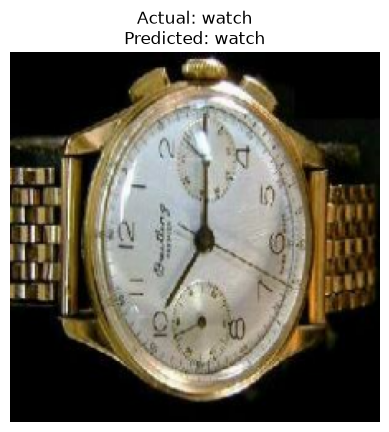

Epoch 1/2
229/229 ━━━━━━━━━━━━━━━━━━━━ 228s 971ms/step - accuracy: 0.9575 - loss: 0.1469 - val_accuracy: 0.9327 - val_loss: 0.2380
Epoch 2/2
229/229 ━━━━━━━━━━━━━━━━━━━━ 239s 1s/step - accuracy: 0.9915 - loss: 0.0537 - val_accuracy: 0.9338 - val_loss: 0.2279
58/58 ━━━━━━━━━━━━━━━━━━━━ 51s 879ms/step - accuracy: 0.9338 - loss: 0.2279
Fine Tuned Test Loss: 0.22789514064788818
Fine Tuned Test Accuracy: 0.9338074326515198


In [1]:

# 5A - Transfer Learning using MobileNetV2

# a. Setup
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Lambda
from tensorflow.keras.models import Sequential

# b. Load dataset
DATA = r"D:\DL\LP IV Updated Datasets\Object Detection\caltech-101"

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA,
    validation_split=0.2,
    subset="training",
    seed=1,
    image_size=(224, 224),
    batch_size=32
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA,
    validation_split=0.2,
    subset="validation",
    seed=1,
    image_size=(224, 224),
    batch_size=32
)

class_names = train_ds.class_names
print("Classes:", len(class_names))

# c. Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# d. Freeze base layers
base_model.trainable = False

model = Sequential([
    Lambda(preprocess_input, input_shape=(224, 224, 3)),
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# e. Training
model.fit(train_ds, validation_data=test_ds, epochs=5)

# f and g. Compute loss and evaluate
loss, accuracy = model.evaluate(test_ds)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# h. Visualize prediction
images, labels = next(iter(test_ds))
predictions = model.predict(images)

i = 0
predicted = np.argmax(predictions[i])

plt.imshow(images[i].numpy().astype("uint8"))
plt.title("Actual: " + class_names[labels[i].numpy()] +
          "\nPredicted: " + class_names[predicted])
plt.axis("off")
plt.show()

# i. Fine tuning
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_ds, validation_data=test_ds, epochs=2)

loss, accuracy = model.evaluate(test_ds)
print("Fine Tuned Test Loss:", loss)
print("Fine Tuned Test Accuracy:", accuracy)
